In [66]:
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, classification_report)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_sample_weight

import pandas as pd
import preprocessing as pp
import encoding as enc
import matplotlib.pyplot as plt
import seaborn as sns


In [45]:


raw = pp.load_raw()
df = pp.clean(raw)

pp.cleaning_report(raw, df)

,rows,columns,duplicate rows,cells missing,text columns
raw,2930,82,0,719,43
cleaned,2930,77,0,649,39


In [50]:
target = enc.make_target(df)


class_counts = target.value_counts().sort_index()

class_percentages = (
    target
    .value_counts(normalize=True)
    .sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

display(class_distribution)

y = enc.make_target(df)

X = df.drop(columns=['SalePrice', 'Price Class'], errors='ignore')

X = enc.encode_features(X)



,Count,Percentage
SalePrice,,
0,237,8.09
1,509,17.37
2,1037,35.39
3,686,23.41
4,397,13.55
5,64,2.18


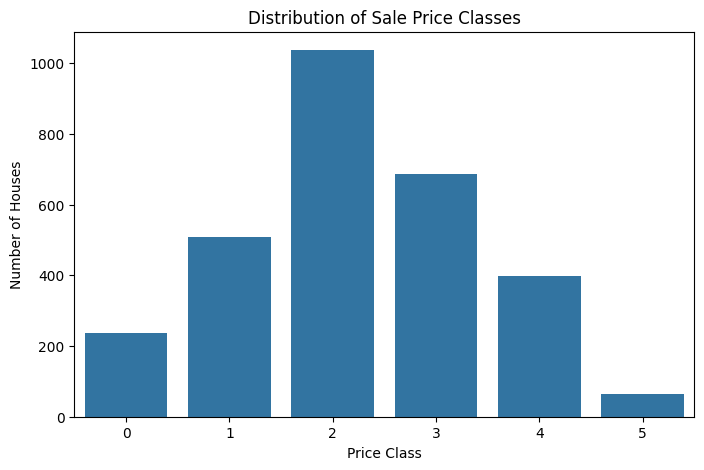

In [51]:
plt.figure(figsize=(8, 5))

sns.countplot(x=target)

plt.title("Distribution of Sale Price Classes")
plt.xlabel("Price Class")
plt.ylabel("Number of Houses")

plt.show()

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print(X_train.shape)
print(X_test.shape)

X_train.head()

(2344, 222)
(586, 222)


,Lot Frontage,Lot Area,Lot Shape,Land Slope,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,Exter Qual,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
2354,81.0,10530,0.0,0.0,6,6,1975,2000,248.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1621,NaN,10147,1.0,0.0,6,5,1994,1994,32.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1155,95.0,19508,0.0,0.0,6,5,1974,1974,144.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2674,65.0,7800,0.0,0.0,5,7,1939,1950,0.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1343,NaN,6120,0.0,0.0,5,6,1945,1995,0.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [54]:
missing = X_train.isnull().sum()
display(missing[missing > 0].sort_values(ascending=False).head(20))

Lot Frontage     399
Garage Yr Blt    123
dtype: int64

In [55]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [60]:
print("Missing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

Missing values in training: 0
Missing values in testing: 0


In [61]:
xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=6,
    eval_metric='mlogloss',
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

In [63]:
xgb_model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets impo

In [64]:
y_pred = xgb_model.predict(X_test)

y_prob = xgb_model.predict_proba(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("Macro F1:", f1_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

Accuracy: 0.7713310580204779
Precision: 0.7678737093431777
Recall: 0.7173302691172422
Macro F1: 0.7380310010878772

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.67      0.70        48
           1       0.70      0.68      0.69       102
           2       0.78      0.86      0.81       207
           3       0.81      0.74      0.78       137
           4       0.80      0.82      0.81        79
           5       0.78      0.54      0.64        13

    accuracy                           0.77       586
   macro avg       0.77      0.72      0.74       586
weighted avg       0.77      0.77      0.77       586



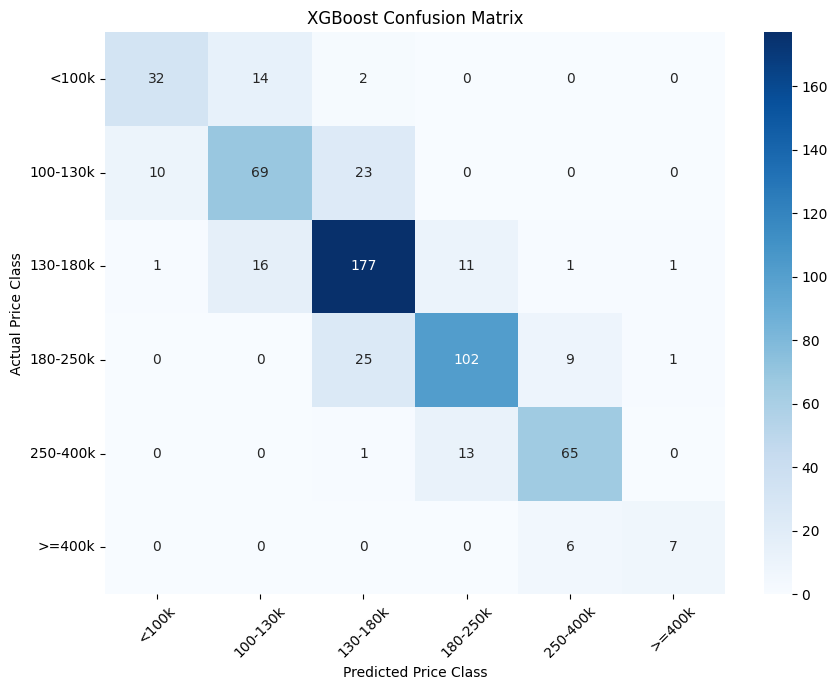

In [67]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=enc.price_labels,
    yticklabels=enc.price_labels
)

plt.xlabel("Predicted Price Class")
plt.ylabel("Actual Price Class")
plt.title("XGBoost Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()